# **Aprendizaje Automático 1 - Trabajo Práctico 2**
## EDA - Predicción de lluvias en Australia

**Integrantes:** Alejandro Acosta, Diego Hauret, Gastón Rinaldi, Agustín Torres

Análisis exploratorio de datos previo a la construcción de un modelo de ...

**Indice:**
1. Carga y comprensión de los datos
2. Análisis de valores faltantes
3. Imputación de valores faltantes (ejemplo)
4. Análisis univariado (variable objetivo y predictoras)
5. Análisis bivariado (correlaciones y relación con MEDV)
6. Multicolinealidad entre predictoras
7. Detección de outliers
8. Conclusiones y próximos pasos


## Diccionario de variables

| Variable | Descripción |
| :--- | :--- |
| **Unnamed** | Índices |
| **Date** | Fecha |
| **Location** | Localidad de ubicación de la estación meteorológica |
| **MinTemp** | Temperatura mínima en °C |
| **MaxTemp** | Temperatura máxima en °C |
| **Rainfall** | Cantidad de lluvia registrada durante las últimas 24 horas (mm) |
| **Evaporation** | Evaporación aparente calculada (medida en mm) |
| **Sunshine** | Número de horas totales de sol brillante registradas a lo largo del día |
| **WindGustDir** | Dirección de la ráfaga de viento más fuerte |
| **WindGustSpeed** | Velocidad de la ráfaga de viento más fuerte |
| **WindDir9am** | Dirección del viento registrada a las 09:00 horas |
| **WindDir3pm** | Dirección del viento registrada a las 15:00 horas |
| **WindSpeed9am** | Velocidad del viento (en km/h). Promedio de los 10 minutos anteriores |
| **WindSpeed3pm** | Velocidad del viento (en km/h). Promedio de los 10 minutos anteriores |
| **Humidity9am** | Porcentaje de humedad relativa registrado a las 09:00 horas |
| **Humidity3pm** | Porcentaje de humedad relativa registrado a las 15:00 horas |
| **Pressure9am** | Presión atmosférica a las 09:00 horas (en hectopascales) |
| **Pressure3pm** | Presión atmosférica a las 15:00 horas (en hectopascales) |
| **Cloud9am** | Nubosidad a las 09:00 horas (0 indica cielo despejado y 8 nublado total) |
| **Cloud3pm** | Nubosidad a las 15:00 horas (0 indica cielo despejado y 8 nublado total) |
| **Temp9am** | Temperatura medida a las 09:00 horas en °C |
| **Temp3pm** | Temperatura medida a las 15:00 horas en °C |
| **RainToday** | Variable categórica binaria (Yes / No). Toma el valor Yes si la precipitación acumulada (Rainfall) en las últimas 24 horas hasta las 09:00 horas de día actual superó el 1.0 mm |
| **RainTomorrow** | Variable objetivo (target) a predecir (Yes / No). Indica si lloverá al día siguiente (las precipitaciones de mañana superarán el umbral de 1.0 mm) |

## 0. Carga de librerías

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             matthews_corrcoef, cohen_kappa_score, log_loss, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Carga y comprensión de los datos

In [10]:
df = pd.read_csv('weatherAUS_2026C2.csv')
print("Dimensiones:", df.shape)
df.head(10)


Dimensiones: (145412, 25)


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6000,22.5000,0.6000,NaN,NaN,W,45.0000,W,WNW,19.0000,25.0000,68.8000,23.8000,1008.1000,1007.2000,8.0000,NaN,16.8000,20.8000,No,No,0.0000
1,1,2008-12-02,Albury,7.3000,25.8000,0.0000,NaN,NaN,WNW,44.0000,NNW,WSW,4.0000,23.0000,40.1000,22.1000,1011.1000,1007.5000,NaN,NaN,18.3000,24.6000,No,No,0.0000
2,2,2008-12-03,Albury,13.2000,26.2000,0.0000,NaN,NaN,WSW,46.0000,W,WSW,20.0000,27.0000,36.2000,31.5000,1007.3000,1009.4000,NaN,2.0000,21.2000,23.4000,No,No,0.0000
3,3,2008-12-04,Albury,10.0000,28.8000,0.0000,NaN,NaN,NE,23.0000,SE,E,10.0000,10.0000,45.8000,18.5000,1017.6000,1012.4000,NaN,NaN,17.4000,26.3000,No,No,1.0000
4,4,2008-12-05,Albury,17.4000,32.4000,1.0000,NaN,NaN,W,41.0000,ENE,NW,6.0000,17.0000,83.5000,34.6000,1010.9000,1005.9000,7.0000,8.0000,17.9000,29.1000,No,No,0.2000
5,5,2008-12-06,Albury,14.5000,30.1000,0.2000,NaN,NaN,WNW,55.0000,W,W,19.0000,24.0000,56.6000,23.0000,1009.9000,1005.5000,NaN,NaN,20.9000,28.2000,No,No,0.0000
6,6,2008-12-07,Albury,15.1000,25.3000,0.0000,NaN,NaN,W,51.0000,SW,W,21.0000,24.0000,46.8000,20.3000,1009.3000,1008.5000,1.0000,NaN,18.3000,24.0000,No,No,0.0000
7,7,2008-12-08,Albury,8.1000,26.1000,0.0000,NaN,NaN,W,34.0000,SSE,W,5.0000,16.0000,46.8000,20.8000,1013.5000,1009.7000,NaN,NaN,17.1000,25.9000,No,No,0.0000
8,8,2008-12-09,Albury,9.5000,31.8000,0.0000,NaN,NaN,NNW,80.0000,SE,NW,6.0000,28.0000,42.1000,8.5000,1008.9000,1003.6000,NaN,NaN,18.0000,28.9000,No,Yes,1.4000
9,9,2008-12-10,Albury,13.4000,30.1000,1.4000,NaN,NaN,W,28.0000,S,SSE,14.0000,12.0000,57.6000,24.6000,1007.2000,1005.7000,NaN,NaN,18.9000,28.2000,Yes,No,0.0000


In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  object 
 2   Location          145412 non-null  object 
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  object 
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  object 
 11  WindDir3pm        141186 non-null  object 
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       13

### Observaciones sobre las columnas del archivo


* Unnamed: 0: es un índice que no aporta información, entonces se elimina.
* RainfallTomorrow: es la **cantidad de lluvia (mm) de mañana**. Es una fuga de información (*data leakage*): RainTomorrow se define justamente como "mañana llovió ≥ 1 mm", por lo que esta columna casi determina el target. En un caso real **no la conoceríamos al momento de predecir**. Se elimina de los predictores.

Date no se usa como número, pero de ella sacamos el **mes** (la lluvia es estacional).

In [12]:
df = df.drop(columns=["Unnamed: 0"])
df["Date"] = pd.to_datetime(df["Date"])

num_cols = df.select_dtypes(include="number").columns.drop("RainfallTomorrow").tolist()
cat_cols = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

print("Período:", df["Date"].min().date(), "->", df["Date"].max().date())
print("Ubicaciones de las estaciones:", df["Location"].nunique())
print("Filas duplicadas:", df.duplicated().sum())
print("\nVariables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)

Período: 2007-11-01 -> 2017-06-24
Ubicaciones de las estaciones: 49
Filas duplicadas: 0

Variables numéricas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Variables categóricas: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


### Variables numéricas: rango de variación y estadísticos

In [13]:
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["%nulos"] = (df[num_cols].isna().mean() * 100).round(1)
print('Estadísticos descriptivos:')
print('=' * 110)
desc.round(2)

Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max,skew,%nulos
MinTemp,143928.0000,12.2000,6.4200,-9.7000,7.6000,12.0000,16.9000,34.1000,0.0200,1.0000
MaxTemp,144159.0000,23.2200,7.1400,-5.1000,17.9000,22.6000,28.2000,49.1000,0.2200,0.9000
Rainfall,142152.0000,2.3600,8.4800,0.0000,0.0000,0.0000,0.8000,371.0000,9.8300,2.2000
Evaporation,82658.0000,5.4700,4.1900,0.0000,2.6000,4.8000,7.4000,145.0000,3.7600,43.2000
Sunshine,75616.0000,7.6100,3.7900,0.0000,4.8000,8.4000,10.6000,14.5000,-0.5000,48.0000
WindGustSpeed,135159.0000,40.0400,13.6500,6.0000,31.0000,38.0000,48.0000,135.0000,0.8700,7.1000
WindSpeed9am,143645.0000,14.0700,8.9400,0.0000,7.0000,13.0000,19.0000,130.0000,0.7900,1.2000
WindSpeed3pm,142351.0000,18.6600,8.8700,0.0000,12.0000,18.0000,24.0000,86.0000,0.6200,2.1000
Humidity9am,142759.0000,68.8600,19.0600,0.0000,57.0000,69.9000,83.1000,100.0000,-0.4900,1.8000
Humidity3pm,140907.0000,51.5300,20.8400,0.0000,36.6000,52.0000,65.7000,100.0000,0.0300,3.1000


### Variables categóricas: cardinalidad y categorías más frecuentes

In [14]:
for c in cat_cols + ["RainTomorrow"]:
    vc = df[c].value_counts(dropna=False)
    print(f"{c}: {df[c].nunique()} categorías | nulos: {df[c].isna().sum()} | top: {vc.head(5).to_dict()}")

Location: 49 categorías | nulos: 0 | top: {'Canberra': 3435, 'Sydney': 3343, 'Darwin': 3192, 'Melbourne': 3192, 'Brisbane': 3192}
WindGustDir: 16 categorías | nulos: 10316 | top: {nan: 10316, 'W': 9910, 'SE': 9416, 'N': 9313, 'SSE': 9215}
WindDir9am: 16 categorías | nulos: 10562 | top: {'N': 11754, nan: 10562, 'SE': 9283, 'E': 9172, 'SSE': 9109}
WindDir3pm: 16 categorías | nulos: 4226 | top: {'SE': 10837, 'W': 10105, 'S': 9924, 'WSW': 9512, 'SSE': 9397}
RainToday: 2 categorías | nulos: 3260 | top: {'No': 110276, 'Yes': 31876, nan: 3260}
RainTomorrow: 2 categorías | nulos: 3259 | top: {'No': 110281, 'Yes': 31872, nan: 3259}


## 2. Análisis de valores faltantes


Revisamos cuántos nulos tiene cada columna y si hay algún patrón (filas con muchos nulos a la vez, o nulos concentrados).


In [15]:
faltante = df.isna().sum().sort_values(ascending=False)
faltante_pct = (faltante / len(df) * 100).round(2)
print("Cantidad de nulos por columna:")
pd.DataFrame({"nulos": faltante, "% nulos": faltante_pct})


Cantidad de nulos por columna:


,nulos,% nulos
Sunshine,69796,48.0000
Evaporation,62754,43.1600
Cloud3pm,59336,40.8100
Cloud9am,55870,38.4200
Pressure9am,15061,10.3600
Pressure3pm,15024,10.3300
WindDir9am,10562,7.2600
WindGustDir,10316,7.0900
WindGustSpeed,10253,7.0500
Humidity3pm,4505,3.1000


Se observa que las variables Sunshine, Evaporation, Cloud3pm y Cloud9am tienen más de 38% de valores faltantes. Esto tendremos que analizarlo más a fondo pues la lógica indica que a mayor nubosidad habrías más probabilidades de lluvias y no deberiamos descartarlos sin antes analizarlos.
La variable RainTomorrow, que es nuestra target, tiene 3259 valores faltantes. Esos registros los tenemos que eliminar.

In [16]:
nulos_por_fila = df.isna().sum(axis=1)
print("Cantidad de nulos por fila:\n",nulos_por_fila.value_counts().sort_index())


Cantidad de nulos por fila:
 0     56412
1     10764
2     18167
3      9920
4     28702
5      3774
6     10432
7      2087
8      1440
9       500
10      388
11      717
12      797
13      130
14      550
15       62
16       82
17      123
18       65
19       23
20       85
21       10
22      182
Name: count, dtype: int64


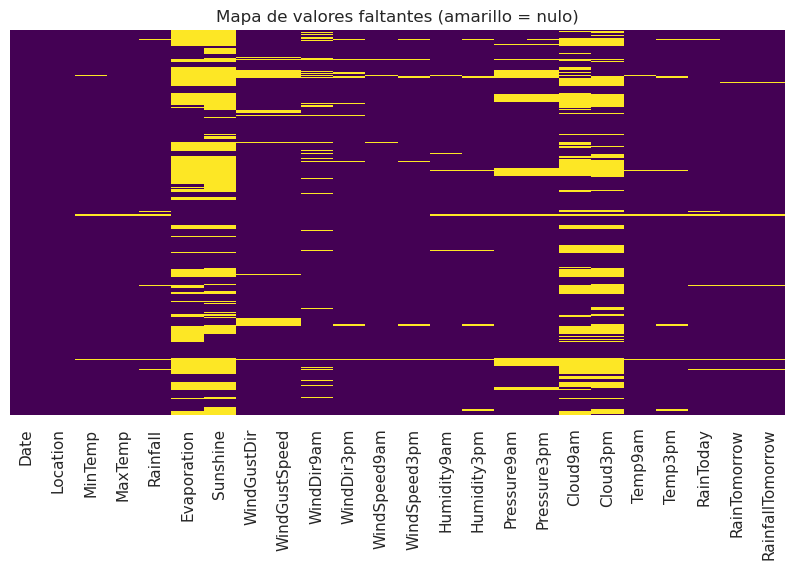

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
#cbar=False desactiva la barra lateral de medidas
#yticklabels=False oculta las etiquetas de valores del eje y
ax.set_title("Mapa de valores faltantes (amarillo = nulo)")
plt.show()


In [18]:
# ¿Los faltantes son aleatorios? Se ve si "estar faltante" depende de la estación meteorológica
faltante_alto = ["Evaporation", "Sunshine", "Cloud9am", "Cloud3pm"]
por_ubicacion = df.groupby("Location")[faltante_alto].agg(lambda s: s.isna().mean()).round(2)
print("Ubicaciones donde la variable NUNCA se mide (100% faltante):")
for c in faltante_alto:
    print(f"  {c}: {(por_ubicacion[c] == 1).sum()} de {len(por_ubicacion)} ubicaciones")
por_ubicacion.sort_values("Sunshine", ascending=False).head(10)

Ubicaciones donde la variable NUNCA se mide (100% faltante):
  Evaporation: 16 de 49 ubicaciones
  Sunshine: 19 de 49 ubicaciones
  Cloud9am: 12 de 49 ubicaciones
  Cloud3pm: 12 de 49 ubicaciones


,Evaporation,Sunshine,Cloud9am,Cloud3pm
Location,,,,
Newcastle,1.0000,1.0000,0.0800,0.3100
Walpole,1.0000,1.0000,1.0000,1.0000
NorahHead,1.0000,1.0000,1.0000,1.0000
Penrith,1.0000,1.0000,1.0000,1.0000
Richmond,0.4600,1.0000,0.8000,0.8100
SalmonGums,1.0000,1.0000,1.0000,1.0000
Launceston,0.9500,1.0000,0.7600,0.7600
Katherine,0.0600,1.0000,0.0300,0.4600
Tuggeranong,1.0000,1.0000,1.0000,1.0000


### Decisión sobre faltantes

| Caso | Variables | Decisión | Justificación |
|---|---|---|---|
| **Target faltante** | `RainTomorrow` (~2 %) | **Se eliminan esas filas** | No se puede entrenar ni evaluar sin etiqueta. Imputar el target inventaría información. |
| **Muy altos (>30 %)** | `Evaporation`, `Sunshine`, `Cloud9am`, `Cloud3pm` | **Imputar con la mediana + agregar una variable indicadora "faltante"** | No se descartan porque `Sunshine` y `Cloud3pm` suelen estar entre los predictores más informativos. Además el faltante **no es aleatorio** (hay estaciones que directamente no miden estas variables), así que "no fue medida" es información en sí misma → la indicadora la captura. |
| **Moderados / bajos** | resto de numéricas | **Imputar con la mediana** (calculada solo con train) | La mediana es robusta a los outliers que vimos. |
| **Categóricas** | `WindGustDir`, `WindDir9am`, `WindDir3pm` | **Categoría propia "Desconocido"** | Evita inventar una dirección de viento. |
| **`RainToday`** | ~2 % | **Se eliminan esas filas** | Es la misma situación que el target (si falta `Rainfall`, falta `RainToday`). |

> La imputación con la mediana se **ajusta únicamente con el conjunto de entrenamiento** para no filtrar información del test.

In [19]:
# Se eliminan las filas sin target o sin RainToday (se hace ANTES de dividir: no usa información de otras filas)
n0 = len(df)
df = df.dropna(subset=["RainTomorrow", "RainToday"]).copy()
print(f"Filas eliminadas: {n0 - len(df)} ({(n0 - len(df)) / n0:.2%}) | Filas restantes: {len(df)}")

Filas eliminadas: 4665 (3.21%) | Filas restantes: 140747


## 3. Análisis univariado



### 3.1 Variable objetivo: RainTomorrow

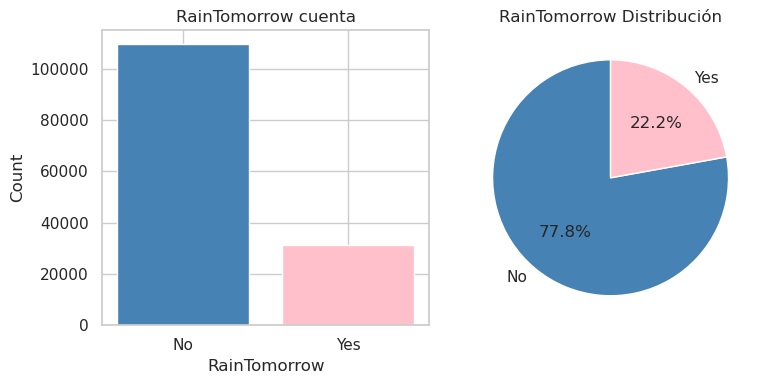

In [20]:
target_cant = df['RainTomorrow'].value_counts()
target_pct = df['RainTomorrow'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Diagrama de barras
axes[0].bar(target_cant.index, target_cant.values, color=['steelblue', 'pink'])
axes[0].set_title('RainTomorrow cuenta')
axes[0].set_xlabel('RainTomorrow')
axes[0].set_ylabel('Count')

# Diagrama de sectores
axes[1].pie(target_pct, labels=target_cant.index, autopct='%1.1f%%',
            colors=['steelblue', 'pink'], startangle=90)
axes[1].set_title('RainTomorrow Distribución')

plt.tight_layout()
plt.show()

El dataset **no está balanceado**: aproximadamente 78 % de los días *no* llueve y 22 % sí llueve.

**Es importante porque:**
* La **accuracy engaña**: un modelo "tonto" que siempre diga *"no lloverá"* acertaría ≈ 78 % sin haber aprendido nada. Por eso hay que mirar **precision, recall, F1, balanced accuracy, ROC-AUC**, etc.
* La regresión logística entrenada con la función de costo estándar tiende a **favorecer la clase mayoritaria** y deja la clase minoritaria (la de interés: "llueve") con **recall bajo**.
* Para la división train/test hay que **estratificar** (conservar la proporción de clases en cada subconjunto). Posibles remedios: class_weight="balanced", *over/undersampling* (p. ej. SMOTE) o ajustar el umbral. Acá probamos class_weight.

### 3.2 Distribución de las predictoras

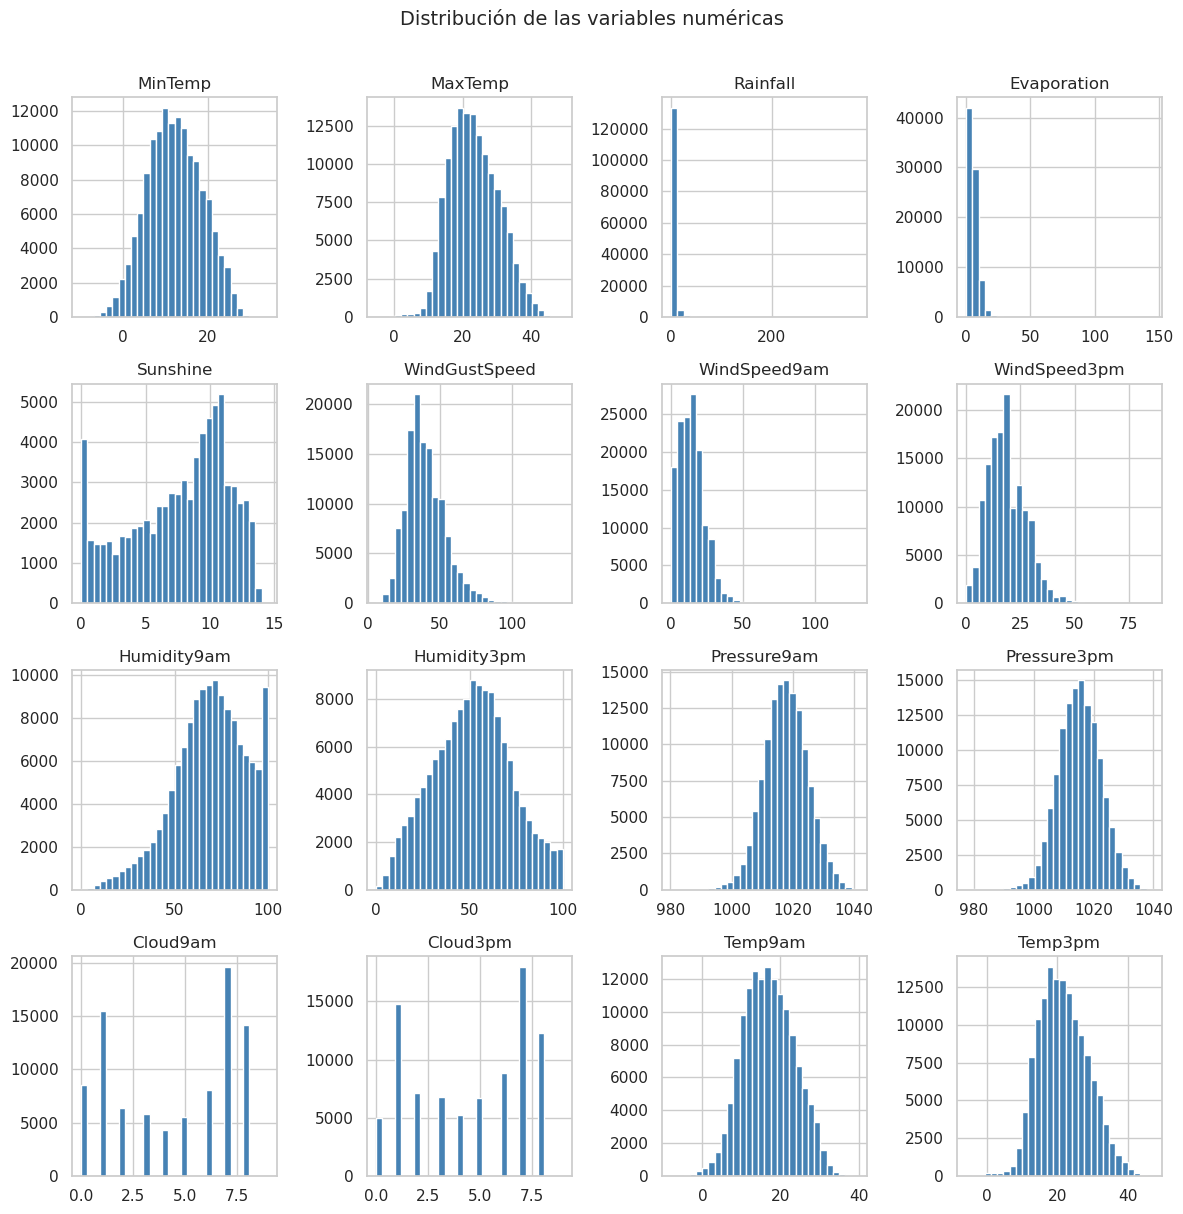

In [21]:
df[num_cols].hist(figsize=(12, 12), bins=30, color='steelblue', edgecolor='white')
plt.suptitle('Distribución de las variables numéricas', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


Cloud9am y Cloud3pm muestran un patrón bimodal.

Rainfall y Evaporation están fuertemente sesgadas a la derecha.

Las características de temperatura y presión siguen una distribución cercana a la normal.

### 3.3 Diagramas de caja según RainTomorrow

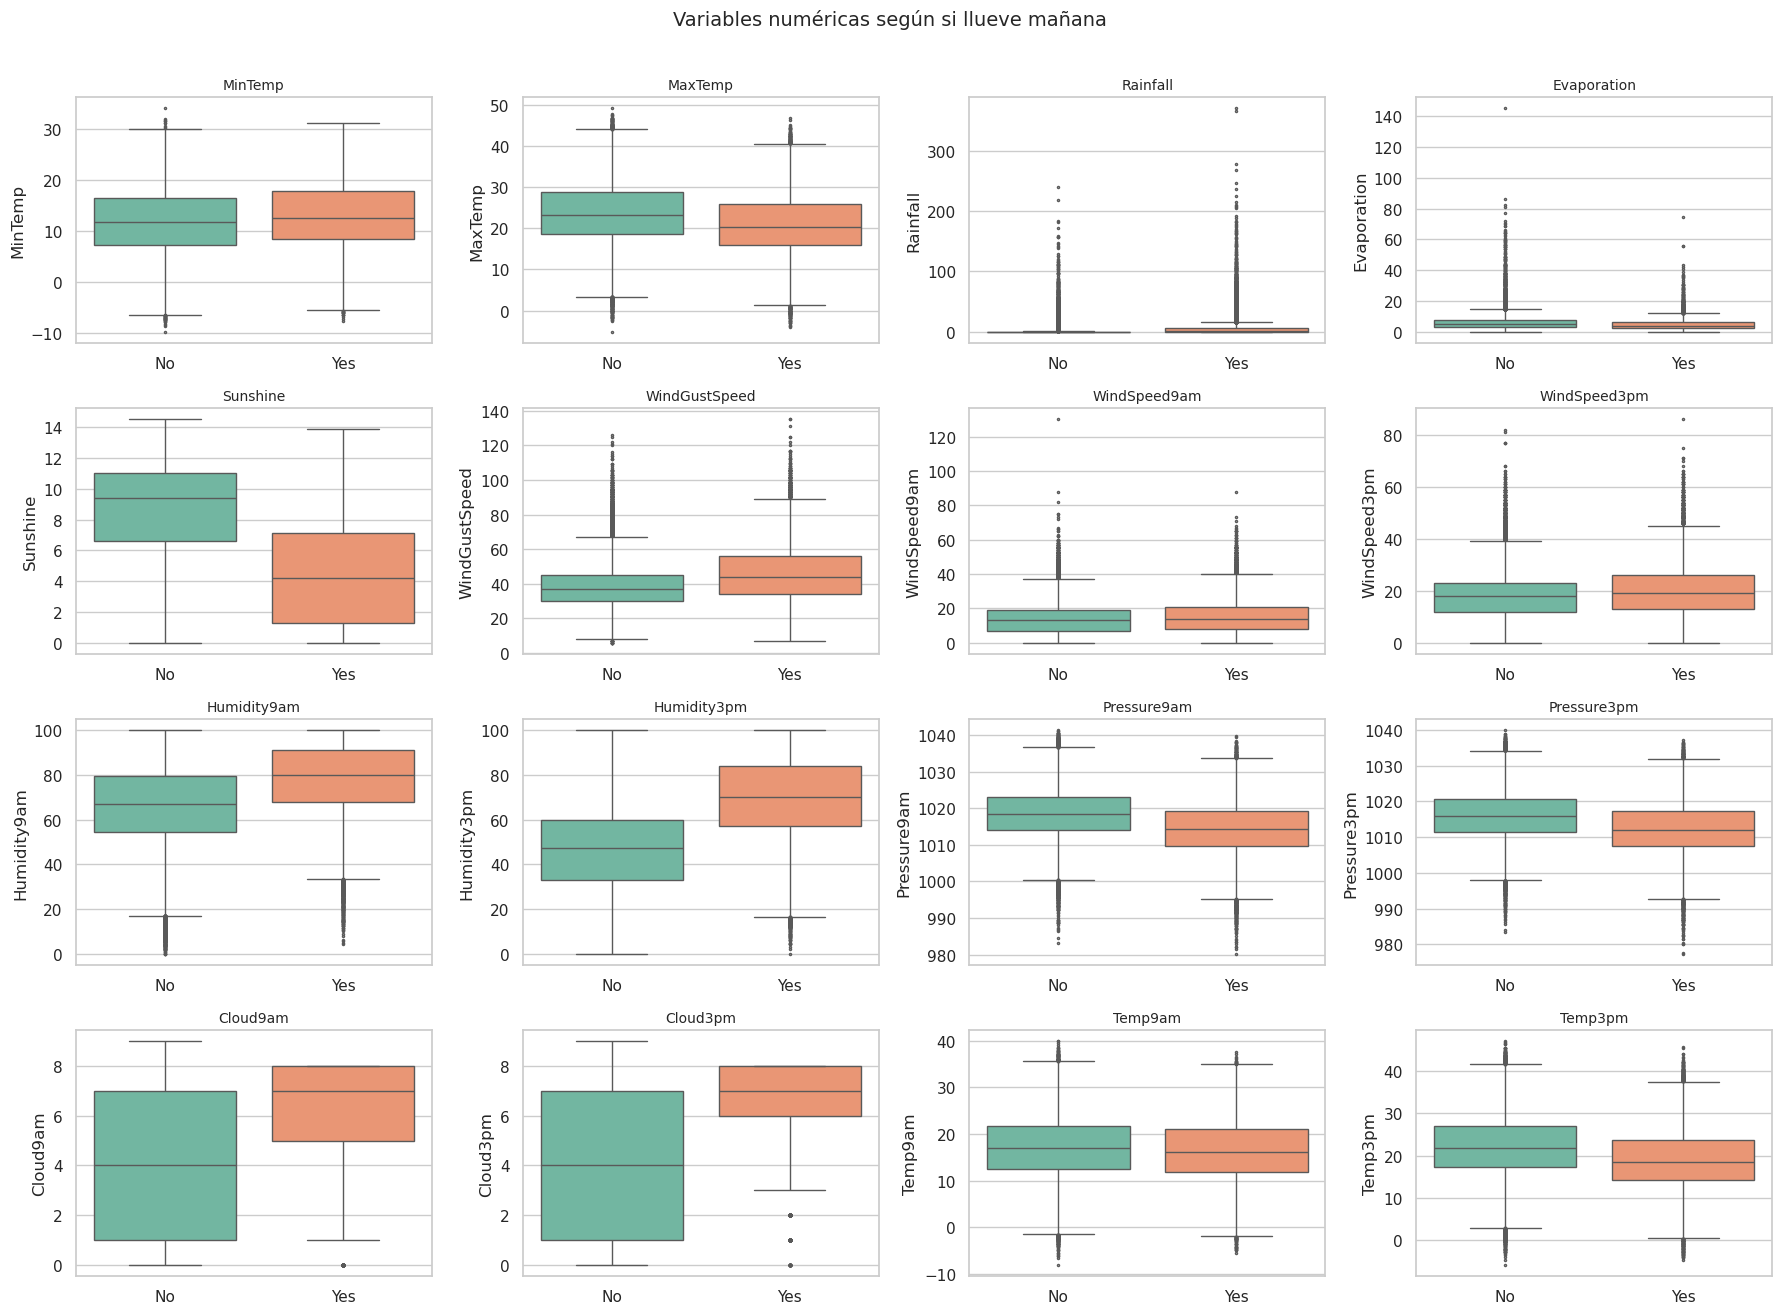

In [22]:
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="RainTomorrow", y=c, ax=ax, palette="Set2", fliersize=1.5)
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.suptitle("Variables numéricas según si llueve mañana", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

### 3.4 Variables categóricas y estacionalidad

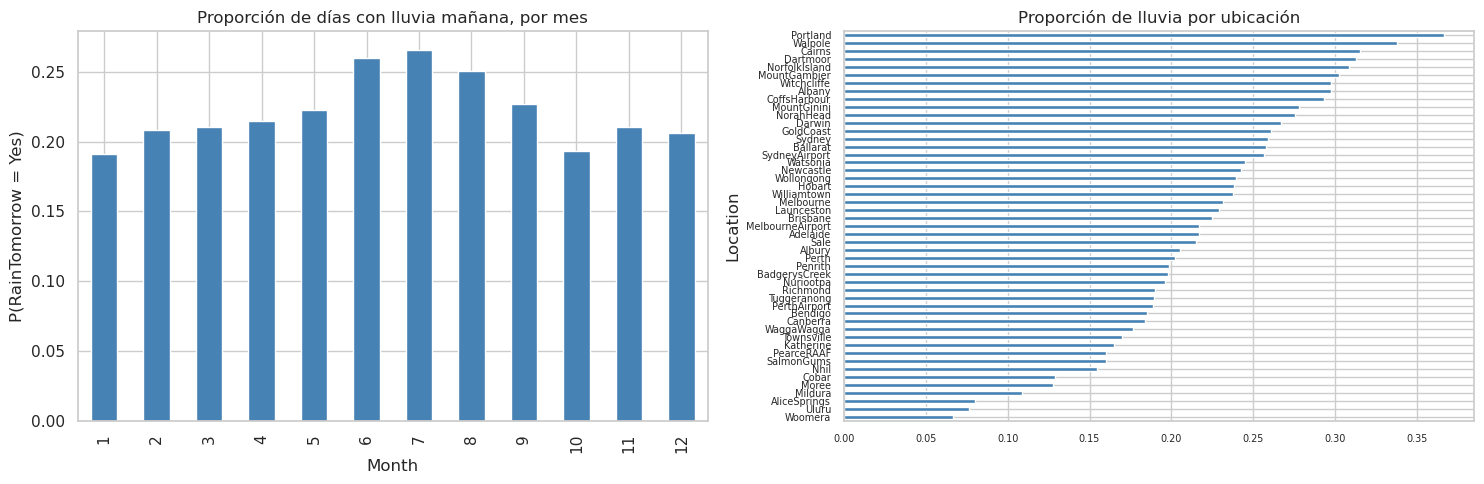

In [23]:
df["Month"] = df["Date"].dt.month
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

(df.groupby("Month")["RainTomorrow"].apply(lambda s: (s == "Yes").mean())
   .plot(kind="bar", ax=axes[0], color="steelblue"))
axes[0].set_title("Proporción de días con lluvia mañana, por mes"); axes[0].set_ylabel("P(RainTomorrow = Yes)")

(df.groupby("Location")["RainTomorrow"].apply(lambda s: (s == "Yes").mean())
   .sort_values().plot(kind="barh", ax=axes[1], color="steelblue", fontsize=7))
axes[1].set_title("Proporción de lluvia por ubicación")

plt.tight_layout(); plt.show()

## 4. Análisis bivariado



### 4.1 Matriz de correlación

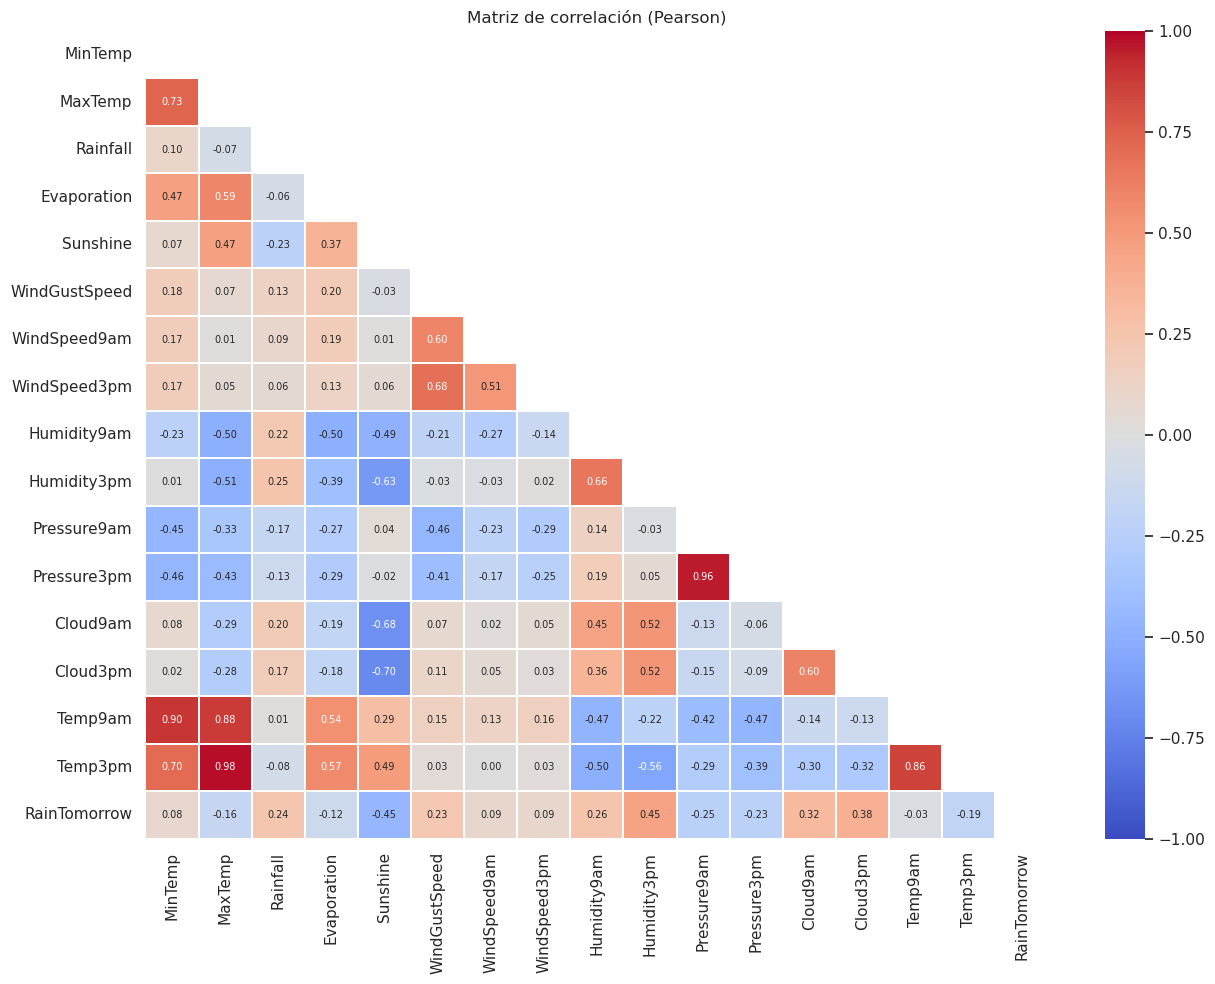

In [24]:
corr_df = df[num_cols].copy()
corr_df["RainTomorrow"] = (df["RainTomorrow"] == "Yes").astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.3, ax=ax)
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

In [25]:
# Correlación de cada variable con el target
print(corr["RainTomorrow"].drop("RainTomorrow").sort_values(key=abs, ascending=False).round(3))

# Pares muy correlacionados entre sí (multicolinealidad)
pairs = (corr.drop(index="RainTomorrow", columns="RainTomorrow").abs().where(np.triu(np.ones((len(num_cols),)*2), 1).astype(bool))
             .stack().sort_values(ascending=False))
print("\nPares con |r| > 0.7:")
print(pairs[pairs > 0.7].round(3))

Sunshine        -0.4520
Humidity3pm      0.4470
Cloud3pm         0.3820
Cloud9am         0.3170
Humidity9am      0.2570
Pressure9am     -0.2480
Rainfall         0.2390
WindGustSpeed    0.2340
Pressure3pm     -0.2280
Temp3pm         -0.1920
MaxTemp         -0.1590
Evaporation     -0.1190
WindSpeed9am     0.0890
WindSpeed3pm     0.0870
MinTemp          0.0840
Temp9am         -0.0250
Name: RainTomorrow, dtype: float64

Pares con |r| > 0.7:
MaxTemp      Temp3pm       0.9800
Pressure9am  Pressure3pm   0.9600
MinTemp      Temp9am       0.8960
MaxTemp      Temp9am       0.8820
Temp9am      Temp3pm       0.8550
MinTemp      MaxTemp       0.7320
Sunshine     Cloud3pm      0.7050
MinTemp      Temp3pm       0.7040
dtype: float64


* Con el target (RainTomorrow) las correlaciones más fuertes son: **Sunshine (−0.45)**, **Humidity3pm (+0.45)**, **Cloud3pm (+0.38)**, Cloud9am (+0.32), Humidity9am (+0.26), Pressure9am (−0.25), Rainfall (+0.24) y WindGustSpeed (+0.23). Esto coincide con la intuición meteorológica.
* Hay **multicolinealidad** entre variables que miden casi lo mismo: Temp3pm–MaxTemp (|r| ≈ 0.98), Pressure9am–Pressure3pm (≈ 0.96), Temp9am–MinTemp (≈ 0.90), Temp9am–MaxTemp (≈ 0.88), etc.
* En regresión logística la multicolinealidad **no arruina la predicción**, pero vuelve **inestables e interpretables con dificultad los coeficientes**. Se usa regularización L2 (por defecto en LogisticRegression), que la mitiga. Conservamos todas las variables, pero debemos tenerlo presente al interpretar los coeficientes.

## 6. Preparación de variables y codificación de categóricas

* Se descartan `RainfallTomorrow` (por fuga) y `Date` (se conserva el mes).
* **Mes** como variable cíclica (`sin`/`cos`) para que diciembre y enero queden "cerca".
* **`RainToday`** y target pasan a 0/1 (codificación binaria).
* **`log1p`** en `Rainfall` y `Evaporation` (muy asimétricas).
* **Indicadoras de faltante** para `Evaporation`, `Sunshine`, `Cloud9am`, `Cloud3pm`.
* **One-hot encoding** para `Location` y las tres direcciones de viento (las categorías nulas del viento pasan a "Desconocido"). Se usa `drop_first=True` para evitar la trampa de variables dummy (colinealidad perfecta).

> Se usa one-hot y no codificación ordinal (0, 1, 2…) porque estas categorías **no tienen un orden natural** y la regresión logística interpretaría la numeración como una magnitud.

In [26]:
data = df.drop(columns=["RainfallTomorrow"]).copy()

# --- indicadoras de faltante (antes de imputar)
#     Creamos la columna xx_faltante que indica si la variable xx está faltante (1) o no (0)
for c in faltante_alto:
    data[f"{c}_faltante"] = data[c].isna().astype(int)

# --- estacionalidad
#     Hace que diciembre y enero estén cerca.
data["Mes_impar"] = np.sin(2 * np.pi * data["Month"] / 12)
data["Mes_par"] = np.cos(2 * np.pi * data["Month"] / 12)

# --- binarizamos "RainToday y "RainTomorrow" que es nuestra variable objetivo (target)
data["RainToday"] = (data["RainToday"] == "Yes").astype(int)
y = (data["RainTomorrow"] == "Yes").astype(int) #variable objetivo (target)

# --- transformación log para variables con distribución sesgada (skew > 1)
data["Rainfall"] = np.log1p(data["Rainfall"])
data["Evaporation"] = np.log1p(data["Evaporation"])

# --- categóricas
cols_viento = ["WindGustDir", "WindDir9am", "WindDir3pm"]
for c in cols_viento:
    data[c] = data[c].fillna("Desconocido")

# drop_first=True para evitar la trampa de variables dummy que pueden generar multicolinealidad.
# La primera columna de cada variable se puede deducir con las demás. 
# El orden de las columnas one-hot es alfabético.
X = data.drop(columns=["RainTomorrow", "Date", "Month"])
X = pd.get_dummies(X, columns=["Location"] + cols_viento, drop_first=True, dtype=int)

print("Shape de X:", X.shape, "| y:", y.shape)
print("Columnas:", X.shape[1], "(numéricas + indicadoras + one-hot)")
X.head(10)

Shape de X: (140747, 119) | y: (140747,)
Columnas: 119 (numéricas + indicadoras + one-hot)


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Evaporation_faltante,Sunshine_faltante,Cloud9am_faltante,Cloud3pm_faltante,Mes_impar,Mes_par,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
0,13.6000,22.5000,0.4700,NaN,NaN,45.0000,19.0000,25.0000,68.8000,23.8000,1008.1000,1007.2000,8.0000,NaN,16.8000,20.8000,0,1,1,0,1,-0.0000,1.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,7.3000,25.8000,0.0000,NaN,NaN,44.0000,4.0000,23.0000,40.1000,22.1000,1011.1000,1007.5000,NaN,NaN,18.3000,24.6000,0,1,1,1,1,-0.0000,1.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,13.2000,26.2000,0.0000,NaN,NaN,46.0000,20.0000,27.0000,36.2000,31.5000,1007.3000,1009.4000,NaN,2.0000,21.2000,23.4000,0,1,1,1,0,-0.0000,1.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,10.0000,28.8000,0.0000,NaN,NaN,23.0000,10.0000,10.0000,45.8000,18.5000,1017.6000,1012.4000,NaN,NaN,17.4000,26.3000,0,1,1,1,1,-0.0000,1.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,17.4000,32.4000,0.6931,NaN,NaN,41.0000,6.0000,17.0000,83.5000,34.6000,1010.9000,1005.9000,7.0000,8.0000,17.9000,29.1000,0,1,1,0,0,-0.0000,1.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
5,14.5000,30.1000,0.1823,NaN,NaN,55.0000,19.0000,24.0000,56.6000,23.0000,1009.9000,1005.5000,NaN,NaN,20.9000,28.2000,0,1,1,1,1,-0.0000,1.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
6,15.1000,25.3000,0.0000,NaN,NaN,51.0000,21.0000,24.0000,46.8000,20.3000,1009.3000,1008.5000,1.0000,NaN,18.3000,24.0000

## 7. División train / validación / test

Se divide antes de imputar y estandarizar, para que la mediana y la media/desvío se calculen solo con los datos de entrenamiento (si no, el test "se filtra" en el preprocesamiento).

* **Train (60 %)**: ajusta el modelo.
* **Validación (20 %)**: se usa para elegir el umbral y comparar configuraciones.
* **Test (20 %)**: se usa una sola vez al final para reportar el desempeño.

La división es **estratificada** por RainTomorrow (por el desbalance de clases).

*Nota:* los datos son series temporales por estación, y una división aleatoria mezcla fechas entre train y test. Lo consideramos como aceptable para este TP (se asume que cada día es una observación independiente), pero en un caso real convendría una **división temporal** (entrenar con el pasado, evaluar con el futuro).

In [27]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nombre:5s}: {len(yy):>7,} filas | % lluvia = {yy.mean():.3%}")

train:  84,448 filas | % lluvia = 22.165%
val  :  28,149 filas | % lluvia = 22.164%
test :  28,150 filas | % lluvia = 22.163%


## 8. Imputación y estandarización (ajustadas solo con train)

La **estandarización** es importante para la regresión logística porque:
* los coeficientes quedan comparables entre variables (están en la misma escala),
* la regularización L2 penaliza por igual a todas las variables (si no, las de mayor escala quedarían favorecidas).

Solo se estandarizan las variables **continuas**; las dummies 0-1 se dejan como están.

In [28]:
continuas = ["MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustSpeed",
             "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm",
             "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm"]

imputer = SimpleImputer(strategy="median").fit(X_train[continuas])      # mediana de TRAIN
scaler = StandardScaler().fit(imputer.transform(X_train[continuas]))    # media y desvío de TRAIN

def preprocesar(Xd):
    Xd = Xd.copy()
    Xd[continuas] = scaler.transform(imputer.transform(Xd[continuas]))
    return Xd

X_train_s, X_val_s, X_test_s = preprocesar(X_train), preprocesar(X_val), preprocesar(X_test)


## 9. Regresión logística

### 9.1 Definimos una función para calculas las métricas.

Definimos el umbral por defecto con umbral=0.5 (ajustable)

In [29]:
# Función para evaluar un modelo con varias métricas, dado un umbral
def metricas(modelo, X, y, umbral=0.5):
    proba = modelo.predict_proba(X)[:, 1]
    pred = (proba >= umbral).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
        "mcc": matthews_corrcoef(y, pred),        
        "log_loss": log_loss(y, proba),
        "brier": brier_score_loss(y, proba),
    }

# accuracy: proporción de predicciones correctas
# balanced_acc: accuracy balanceada (útil para datasets desbalanceados)
# precision: proporción de predicciones positivas que son correctas
# recall: proporción de ejemplos positivos que son correctamente predichos
# f1: media armónica de precision y recall
# roc_auc: área bajo la curva ROC
# pr_auc: área bajo la curva de precisión-recall (útil para datasets desbalanceados, evalua el modelo en todos los umbrales)
# mcc: coeficiente de correlación de Matthews (útil para datasets desbalanceados, evalua el modelo en todos los umbrales)
# log_loss: pérdida logarítmica
# brier: pérdida de Brier

**accuracy**: proporción de predicciones correctas

**balanced_acc**: accuracy balanceada (útil para datasets desbalanceados)

**precision**: proporción de predicciones positivas que son correctas

**recall**: proporción de ejemplos positivos que son correctamente predichos

**f1**: media armónica de precision y recall

**roc_auc**: área bajo la curva ROC

**pr_auc**: área bajo la curva de precisión-recall, útil para datasets desbalanceados (evalua el modelo en todos los umbrales)

**mcc**: coeficiente de correlación de Matthews (útil para datasets desbalanceados). El resultado de la función siempre se sitúa en un rango estricto de -1 a +1. (Predicción perfecta: +1, Predicción aleatoria: 0, Predicción inversa: -1)

**log_loss**: pérdida logarítmica

**brier**: pérdida de Brier

## 9.2 Se entrenan dos modelos y se comparan.

- Regresión logística estandar (lr)
- Regresión logística con class_weight="balanced" para que tenga en cuenta la clase minritaria "No llueve" (lr_bal)

In [30]:
# Regresión logística sin y con class_weight, para ver cómo afecta el desbalance
# Regularización Ridge L2 por defecto (penalty='l2')
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced",
                            random_state=RANDOM_STATE).fit(X_train_s, y_train)



### 9.3 Metricas con el umbral por defecto (0.5)

In [31]:
res = pd.DataFrame({
    "LogReg": metricas(lr, X_val_s, y_val),
    "LogReg balanced": metricas(lr_bal, X_val_s, y_val),
}).T
res

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,mcc,log_loss,brier
LogReg,0.8524,0.7328,0.7382,0.5179,0.6087,0.8760,0.7064,0.5336,0.3450,0.1073
LogReg balanced,0.7960,0.7912,0.5268,0.7825,0.6297,0.8770,0.7043,0.5147,0.4421,0.1420


### 9.4 Matrices de confusión (umbral 0.5, sobre validación)
Atención porque las matrices están traspuestas respecto a lo visto en la teoría (estándar de sklearn)

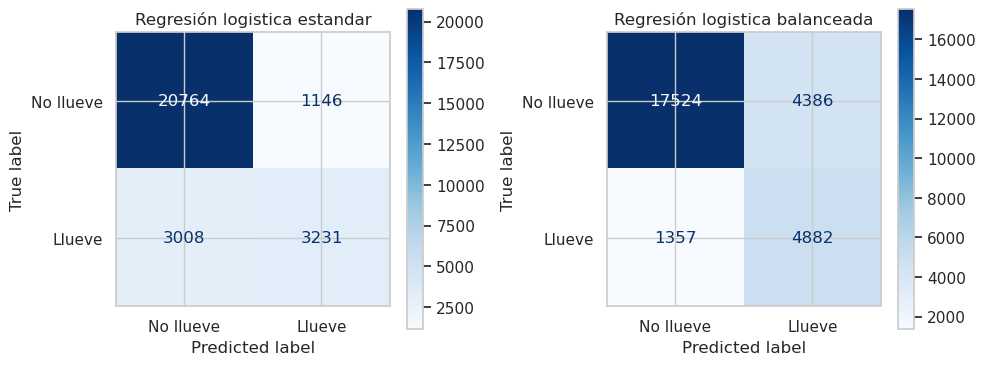

Ubicación de las columas de la matriz de confusión - Y según la teoría
               VN  |  FP                                VP  |  FP
               ---------                                ---------
               FN  |  VP                                FN  |  VN


In [32]:
# Matrices de confusión en validación (umbral 0.5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, m) in zip(axes, [("Regresión logistica estandar", lr), ("Regresión logistica balanceada", lr_bal)]):
    ConfusionMatrixDisplay.from_estimator(m, X_val_s, y_val, ax=ax, cmap="Blues",
                                          display_labels=["No llueve", "Llueve"])
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

print("Ubicación de las columas de la matriz de confusión - Y según la teoría")
print("               VN  |  FP                                VP  |  FP")
print("               ---------                                ---------")
print("               FN  |  VP                                FN  |  VN")

### Falsos positivos vs. falsos negativos

- **Falso positivo (FP):** el modelo predice *"llueve mañana"* y **no llueve** (una falsa alarma).
- **Falso negativo (FN):** el modelo predice *"no llueve"* y **sí llueve**. 

**¿Cuál es más grave?** Depende de la aplicación. Para un pronóstico general, un FN (no avisar de la lluvia) suele ser **más costoso** que un FP (avisar de más), así que interesa un **recall alto**. Si en cambio la alarma tiene un costo grande (p. ej. cancelar un evento), pesa más la **precision**. Esta decisión se traduce en la elección del umbral.

Se ve que el **modelo estándar comete muchos más FN** (recall bajo, por el desbalance), mientras que `class_weight="balanced"` **baja los FN a costa de más FP**.

### 9.5 Curvas ROC

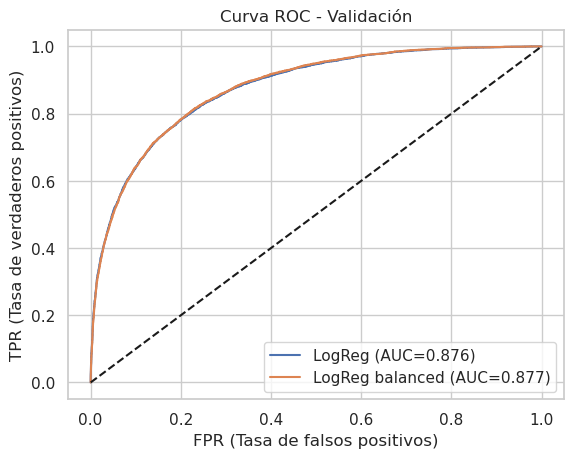

In [33]:
for nombre, m in [("LogReg", lr), ("LogReg balanced", lr_bal)]:
    p = m.predict_proba(X_val_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p)
    auc = roc_auc_score(y_val, p)

    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")

# Línea de referencia: clasificador aleatorio
plt.plot([0, 1], [0, 1], "k--")

plt.title("Curva ROC - Validación")
plt.xlabel("FPR (Tasa de falsos positivos)")
plt.ylabel("TPR (Tasa de verdaderos positivos)")
plt.legend()
plt.grid(True)

Ambas variantes tienen prácticamente la misma curva ROC (mismo AUC). Cada punto de la curva corresponde a un umbral distinto.

Este no lo entiendo y ya es tarde.
Mañana lo veo.

Umbral que maximiza F1: 0.29 | Umbral de Youden: 0.22


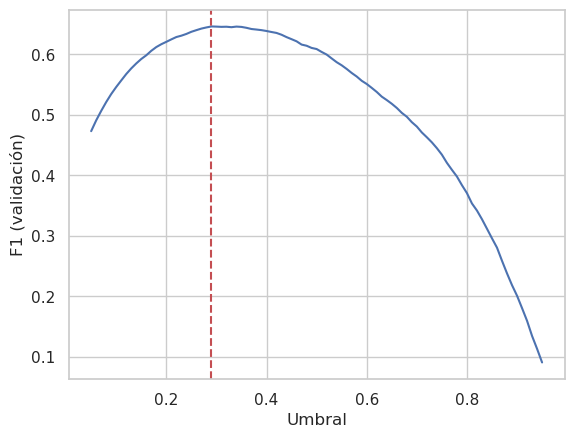

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,mcc,kappa,log_loss,brier
umbral 0.5,0.8524,0.7328,0.7382,0.5179,0.6087,0.8760,0.7064,0.5336,0.5212,0.3450,0.1073
umbral 0.29,0.8266,0.7863,0.5898,0.7141,0.6460,0.8760,0.7064,0.5368,0.5325,0.3450,0.1073


In [34]:
# Umbral óptimo elegido sobre VALIDACIÓN (no sobre test): maximizamos F1 y comparamos con Youden
p_val = lr.predict_proba(X_val_s)[:, 1]
umbrales = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_val, (p_val >= t).astype(int)) for t in umbrales]
umbral_f1 = umbrales[int(np.argmax(f1s))]

fpr, tpr, thr = roc_curve(y_val, p_val)
umbral_youden = thr[int(np.argmax(tpr - fpr))]
print(f"Umbral que maximiza F1: {umbral_f1:.2f} | Umbral de Youden: {umbral_youden:.2f}")

plt.plot(umbrales, f1s); plt.axvline(umbral_f1, color="r", ls="--")
plt.xlabel("Umbral"); plt.ylabel("F1 (validación)"); plt.show()

pd.DataFrame({"umbral 0.5": metricas(lr, X_val_s, y_val, 0.5),
              f"umbral {umbral_f1:.2f}": metricas(lr, X_val_s, y_val, umbral_f1)}).T

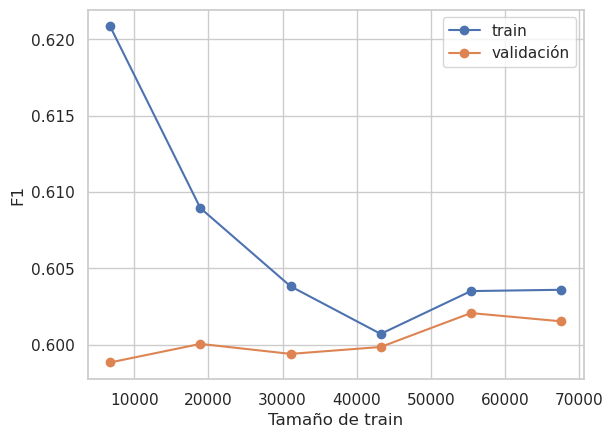

In [35]:
# Curva de aprendizaje para ver si hay under/overfitting
sizes, tr, va = learning_curve(LogisticRegression(max_iter=1000), X_train_s, y_train,
                               cv=5, scoring="f1", train_sizes=np.linspace(0.1, 1, 6),
                               n_jobs=-1, random_state=RANDOM_STATE)
plt.plot(sizes, tr.mean(axis=1), "o-", label="train")
plt.plot(sizes, va.mean(axis=1), "o-", label="validación")
plt.xlabel("Tamaño de train"); plt.ylabel("F1"); plt.legend(); plt.show()

## 10. Implementación del modelo base

In [36]:
# Crear el modelo base (estrategia 'most_frequent' o 'stratified')
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train_s, y_train)

# Predicciones
y_pred_base = baseline.predict(X_test_s)
y_prob_base = baseline.predict_proba(X_test_s)[:, 1] # Si la estrategia genera probabilidades

### 10.1 Repetimos los pasos de evaluación

In [38]:
# Reporte de métricas (Accuracy, Precision, Recall, F1-score)
print("--- Métricas del Modelo Base (Baseline) ---")
print(classification_report(y_test, y_pred_base))

--- Métricas del Modelo Base (Baseline) ---
              precision    recall  f1-score   support

           0       0.78      1.00      0.88     21911
           1       0.00      0.00      0.00      6239

    accuracy                           0.78     28150
   macro avg       0.39      0.50      0.44     28150
weighted avg       0.61      0.78      0.68     28150



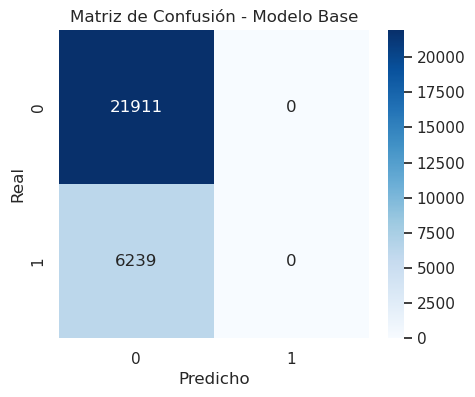

In [39]:
# Matriz de Confusión
plt.figure(figsize=(5, 4))
cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusión - Modelo Base")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

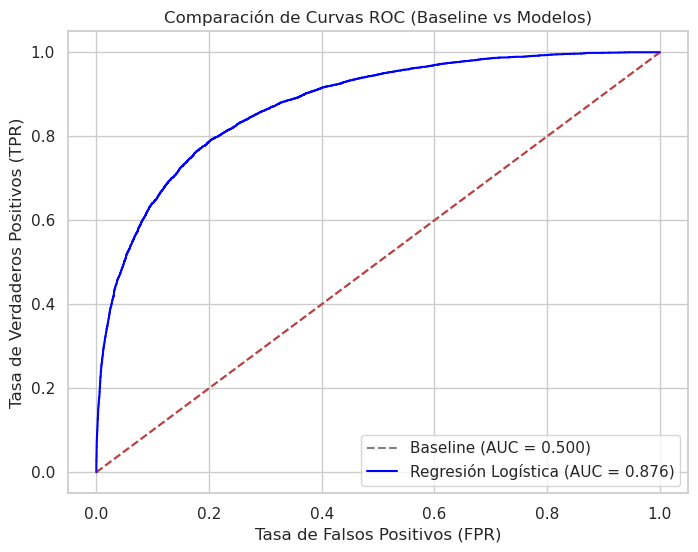

In [ ]:
# C. Curva ROC y cálculo de AUC (para comparar con la Regresión Logística)
fpr_base, tpr_base, _ = roc_curve(y_test, y_prob_base)
auc_base = roc_auc_score(y_test, y_prob_base)


plt.figure(figsize=(8, 6))
plt.plot(fpr_base, tpr_base, label=f'Baseline (AUC = {auc_base:.3f})', linestyle='--', color='gray')

# Grafico de Regresión Logística en el mismo gráfico:
y_prob_lr = lr.predict_proba(X_test_s)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Regresión Logística (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})', color='blue')

plt.plot([0, 1], [0, 1], 'k--', color='red', alpha=0.5) # Línea diagonal de referencia
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Comparación de Curvas ROC (Baseline vs Modelos)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()